# Práctica 1 – Clasificación de estilos artísticos con redes convolucionales

**Aprendizaje Automático II · 2026-27**

Clasificador de imágenes de cuadros en 7 estilos artísticos (*Baroque, Cubism, Impressionism, Minimalism, Pointillism, Pop Art, Ukiyo-e*) con 300 imágenes por clase (2100 en total), implementado en PyTorch con redes convolucionales, pooling, dropout y parada anticipada.

## 1. Carga de datos

In [15]:
import torch
import os
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms
import matplotlib.pyplot as plt

In [16]:
raiz_AA2 = os.getcwd()

In [3]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [20]:
ruta_dataset = os.path.join(raiz_AA2, 'dataset')

dataset = ImageFolder(
    root=ruta_dataset,
    transform=transform
)

print("Número de imágenes:", len(dataset))
print("Clases:", dataset.classes)
print("Etiquetas:", dataset.class_to_idx)

Número de imágenes: 2100
Clases: ['Baroque', 'Cubism', 'Impressionism', 'Minimalism', 'Pointillism', 'Pop_Art', 'Ukiyo']
Etiquetas: {'Baroque': 0, 'Cubism': 1, 'Impressionism': 2, 'Minimalism': 3, 'Pointillism': 4, 'Pop_Art': 5, 'Ukiyo': 6}


### División estratificada en entrenamiento (70 %), validación (15 %) y test (15 %)

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))
etiquetas = dataset.targets

In [6]:
indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

print("Entrenamiento:", len(indices_train))
print("Validación:", len(indices_val))
print("Test:", len(indices_test))

Entrenamiento: 1470
Validación: 315
Test: 315


In [7]:
from torch.utils.data import Subset

train_dataset = Subset(dataset, indices_train)
val_dataset = Subset(dataset, indices_val)
test_dataset = Subset(dataset, indices_test)

loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [8]:
# Acceder a los datos por lotes
for X, y in loader:
    print(f'Tamaño batch X: {X.shape}')
    print(f'Tamaño batch y: {y.shape}')
    print(X)
    print(f'Etiquetas: {y}')
    break

Tamaño batch X: torch.Size([32, 3, 128, 128])
Tamaño batch y: torch.Size([32])
tensor([[[[0.1843, 0.1686, 0.1725,  ..., 0.5961, 0.6627, 0.6588],
          [0.1882, 0.1608, 0.1843,  ..., 0.5725, 0.6353, 0.6431],
          [0.2000, 0.1725, 0.2000,  ..., 0.5569, 0.6431, 0.6549],
          ...,
          [0.4275, 0.3922, 0.3843,  ..., 0.5373, 0.5294, 0.4863],
          [0.4039, 0.4118, 0.4118,  ..., 0.5569, 0.5373, 0.4706],
          [0.5255, 0.4784, 0.4745,  ..., 0.5647, 0.5333, 0.5255]],

         [[0.1373, 0.1412, 0.1451,  ..., 0.6196, 0.6784, 0.6667],
          [0.1569, 0.1451, 0.1765,  ..., 0.6039, 0.6667, 0.6706],
          [0.1765, 0.1569, 0.1922,  ..., 0.6039, 0.6706, 0.6824],
          ...,
          [0.2588, 0.2078, 0.1882,  ..., 0.5059, 0.5020, 0.4627],
          [0.1882, 0.2118, 0.2275,  ..., 0.5216, 0.5176, 0.4471],
          [0.3725, 0.3020, 0.2863,  ..., 0.5255, 0.5059, 0.5216]],

         [[0.1686, 0.1725, 0.1882,  ..., 0.6627, 0.7059, 0.6941],
          [0.2039, 0.1922, 0.

## 2. Primeras pruebas (configuraciones 1 y 2)

Red convolucional de partida, igual a la vista en clase para la lengua de signos (3 bloques conv → ReLU → max pooling, una capa oculta de 128 neuronas y dropout), adaptada a imágenes de 128×128 y 7 clases.

In [9]:
import torch.nn as nn
import torch.nn.functional as F

class ConvNet(nn.Module):
  def __init__(self):
    super(ConvNet,self).__init__()
    # primera capa convolucional: 3 canales de entrada (RGB), 16 filtros, tamaño del kernel 5x5
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=5, stride=1, padding=2)

    # segunda capa convolucional: 16 canales de entrada, 32 filtros, tamaño del kernel 5x5
    self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=2)

    # tercera capa convolucional: 32 canales de entrada, 64 filtros, tamaño del kernel 5x5
    self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2)

    # capa de pooling (muestreo): tamaño del kernel 2x2, stride 2
    self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

    # capa de dropout para evitar overfitting
    self.dropout1 = nn.Dropout(p=0.25)

    # capas totalmente conectadas (fully connected layers)
    self.fc1 = nn.Linear(64*16*16, 128)
    # cuarta capa totalmente conectada: 128 neuronas, 7 salidas (una por cada clase)
    self.fc2 = nn.Linear(128, 7)

  def forward(self,x):
    # primer bloque convolucional: conv -> relu -> pool
    x = self.conv1(x)
    x = F.relu(x)
    x = self.pool1(x) # x es un tensor de 64x64 x 16 características

    # segundo bloque convolucional: conv -> relu -> pool
    x = self.pool1(F.relu(self.conv2(x))) # 32x32 x 32 características

    # tercer bloque convolucional: conv -> relu -> pool
    x = self.pool1(F.relu(self.conv3(x))) # 16x16 x 64 características

    # convierte la salida de la última capa convolucional en un vector 1D para la capa totalmente conectada. view es similar a reshape en numpy
    x = x.view(-1, 64*16*16)

    x = F.relu(self.fc1(x))
    x = self.dropout1(x)

    x = self.fc2(x)

    return x


In [10]:
import torch
import torch.optim as optim

# detección si hay una GPU disponible, si no, se usará la CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'*** Utilizando {device}')

# definimos el modelo, la función de pérdida y el optimizador
modelo = ConvNet().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr = 0.001)

print(f'*** Modelo cargado')

# indicamos el número de épocas
epocas = 20

*** Utilizando cpu
*** Modelo cargado


In [11]:
import copy

valores_perdida_train = []
valores_perdida_validacion = []

mejor_perdida = float('inf')
paciencia = 5
epocas_sin_mejora = 0

print('*** Comienza entrenamiento')

# bucle principal de entrenamiento
for epoca in range(epocas):

  modelo.train()

  train_loss = 0.0
  for images, labels in loader:

    # enviamos las imágenes y etiquetas al dispositivo (GPU o CPU)
    images, labels = images.to(device), labels.to(device)

    # resetear los gradientes del optimizador
    optimizador.zero_grad()

    # calculamos la salida del modelo, la pérdida y realizamos backpropagation
    outputs = modelo(images)
    loss = criterio(outputs, labels)
    loss.backward()
    optimizador.step()

    train_loss += loss.item()

  valores_perdida_train.append(train_loss/len(loader))

  with torch.no_grad():
    modelo.eval()

    valid_loss = 0.0
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = modelo(images)
      loss = criterio(outputs, labels)
      valid_loss += loss.item()

    valid_loss = valid_loss/len(val_loader)
    valores_perdida_validacion.append(valid_loss)

  print(f'Época {epoca+1:2d}, train loss: {valores_perdida_train[-1]:.4f} validation loss: {valid_loss:.4f}')

  # parada anticipada
  if valid_loss < mejor_perdida:
    mejor_perdida = valid_loss
    mejor_modelo = copy.deepcopy(modelo.state_dict())
    epocas_sin_mejora = 0
  else:
    epocas_sin_mejora += 1

  if epocas_sin_mejora >= paciencia:
    print('*** Parada anticipada')
    break

modelo.load_state_dict(mejor_modelo)


*** Comienza entrenamiento
Época  1, train loss: 1.9023 validation loss: 1.8305
Época  2, train loss: 1.7770 validation loss: 1.7532
Época  3, train loss: 1.6791 validation loss: 1.6137
Época  4, train loss: 1.5883 validation loss: 1.5395
Época  5, train loss: 1.4581 validation loss: 1.4649
Época  6, train loss: 1.3016 validation loss: 1.4874
Época  7, train loss: 1.2287 validation loss: 1.5132
Época  8, train loss: 1.0590 validation loss: 1.5552
Época  9, train loss: 0.9630 validation loss: 1.5570
Época 10, train loss: 0.8393 validation loss: 1.6513
*** Parada anticipada


<All keys matched successfully>

In [12]:
modelo.eval()

correctas = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = modelo(images)
        _, predicciones = torch.max(outputs, 1)

        total += labels.size(0)
        correctas += (predicciones == labels).sum().item()

accuracy = 100 * correctas / total

print(f'Accuracy de validación: {accuracy:.2f}%')

Accuracy de validación: 45.40%


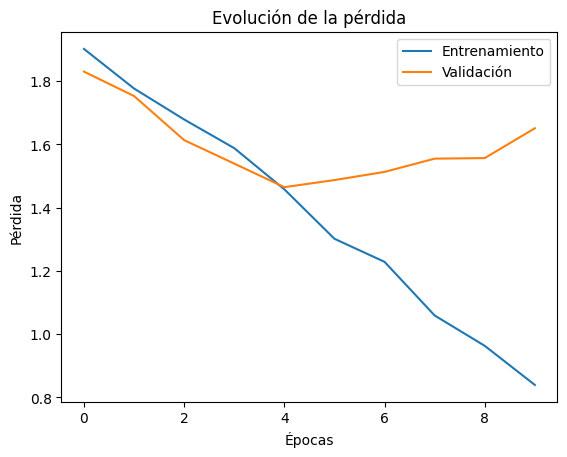

In [13]:
plt.plot(valores_perdida_train, label='Entrenamiento')
plt.plot(valores_perdida_validacion, label='Validación')

plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.show()